# Pol-ISAR ResNet18 Conventional-CNN Baseline: Rigorous 100-Epoch Rerun

This notebook reruns the conventional magnitude-only ResNet18 baseline with a
fixed, leakage-safe protocol. It uses the official train/validation/test split,
fits preprocessing statistics on training data only, selects a checkpoint using
validation macro-F1, and evaluates the test split only after model selection.

**Primary scientific question:** how well can a conventional real-valued CNN
classify the six satellite classes when it receives all four polarimetric
magnitudes (HH, HV, VH, VV) but no phase information?

## 1. Runtime and imports

In Colab, select **Runtime > Change runtime type > T4 GPU** before running.
No package downgrades are performed; this avoids the Pillow/MMCV dependency
failures encountered in earlier detection notebooks.

In [1]:
import hashlib
import json
import math
import os
import platform
import random
import re
import shutil
import time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from torch.utils.data import DataLoader, Dataset
from torchvision.models import resnet18
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.15
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
scikit-learn: 1.6.1
CUDA available: True
GPU: Tesla T4


## 2. Mount Drive and freeze the experiment configuration

The architecture is deliberately the same conventional baseline family as the
earlier experiment: ResNet18 trained from scratch, with its first convolution
changed from 3 to 4 channels and its final layer changed to 6 classes.

In [2]:
try:
    from google.colab import drive
except ImportError:
    print("Google Drive mount skipped outside Colab.")
else:
    # MyDrive can exist as a stale empty directory after a runtime restart. The
    # project folder is a stronger mount check than the mountpoint alone.
    if not Path("/content/drive/MyDrive/drdo").is_dir():
        print("MyDrive/drdo is unavailable; forcing a clean Drive remount.")
        drive.mount("/content/drive", force_remount=True)
    else:
        print("Drive is mounted and MyDrive/drdo is visible.")


@dataclass(frozen=True)
class Config:
    data_root: str = "/content/drive/MyDrive/drdo/Pol_ISARSpaceTarget1.0"
    output_dir: str = "/content/drive/MyDrive/drdo/outputs/resnet18_100epoch_rigorous"
    persistent_cache_dir: str = "/content/drive/MyDrive/drdo/cache/resnet18_mag_log1p_224_v1"
    local_cache_dir: str = "/content/resnet18_mag_log1p_224_v1"
    image_size: int = 224
    batch_size: int = 32
    num_workers: int = 2
    epochs: int = 100
    learning_rate: float = 3e-4
    minimum_learning_rate: float = 1e-6
    weight_decay: float = 1e-4
    label_smoothing: float = 0.1
    gradient_clip_norm: float = 1.0
    augmentation_degrees: float = 5.0
    augmentation_translate: float = 0.03
    augmentation_scale_min: float = 0.95
    augmentation_scale_max: float = 1.05
    augmentation_noise_std: float = 0.01
    seed: int = 42
    expected_train: int = 1314
    expected_valid: int = 162
    expected_test: int = 162
    strict_counts: bool = True


cfg = Config()

# Resolve both the normal Drive layout and an accidental extra extraction level.
def has_official_split_layout(root: Path) -> bool:
    return all((root / "ImageSets" / "images" / split).is_dir() for split in ("train", "valid", "test"))


def resolve_dataset_root(preferred: Path) -> Path:
    candidates = [preferred, Path.cwd() / "Pol_ISARSpaceTarget1.0"]
    drive_project = Path("/content/drive/MyDrive/drdo")
    if drive_project.is_dir():
        # Covers MyDrive/drdo/<dataset>/ImageSets/images/train and one extra
        # nested extraction directory without recursively scanning every .dat.
        train_patterns = (
            "*/ImageSets/images/train",
            "*/*/ImageSets/images/train",
        )
        for pattern in train_patterns:
            for train_dir in drive_project.glob(pattern):
                candidates.append(train_dir.parents[2])

    checked = []
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in checked:
            continue
        checked.append(candidate)
        if has_official_split_layout(candidate):
            return candidate

    my_drive = Path("/content/drive/MyDrive")
    available = sorted(path.name for path in my_drive.iterdir()) if my_drive.is_dir() else []
    raise FileNotFoundError(
        "Could not locate a complete Pol-ISAR dataset. Required relative path: "
        "ImageSets/images/train, valid, and test. "
        f"Checked: {[str(path) for path in checked]}. "
        f"Available entries under MyDrive: {available[:30]}. "
        "Confirm that Colab is mounted to the Google account containing MyDrive/drdo."
    )


resolved_data_root = resolve_dataset_root(Path(cfg.data_root))
object.__setattr__(cfg, "data_root", str(resolved_data_root))

# Permit local verification without changing Drive output behavior in Colab.
if not str(resolved_data_root).startswith("/content/drive/"):
    object.__setattr__(cfg, "output_dir", str((Path.cwd() / "outputs" / "resnet18_100epoch_rigorous").resolve()))
    object.__setattr__(cfg, "persistent_cache_dir", str((Path.cwd() / "cache" / "resnet18_mag_log1p_224_v1").resolve()))
    object.__setattr__(cfg, "local_cache_dir", str((Path.cwd() / "cache" / "resnet18_mag_log1p_224_v1_local").resolve()))

DATA_ROOT = Path(cfg.data_root)
OUT_DIR = Path(cfg.output_dir)
PERSISTENT_CACHE = Path(cfg.persistent_cache_dir)
LOCAL_CACHE = Path(cfg.local_cache_dir)
OUT_DIR.mkdir(parents=True, exist_ok=True)
PERSISTENT_CACHE.mkdir(parents=True, exist_ok=True)
LOCAL_CACHE.mkdir(parents=True, exist_ok=True)

(OUT_DIR / "config.json").write_text(json.dumps(asdict(cfg), indent=2), encoding="utf-8")
print("Resolved DATA_ROOT:", DATA_ROOT)
print(json.dumps(asdict(cfg), indent=2))

MyDrive/drdo is unavailable; forcing a clean Drive remount.
Mounted at /content/drive
Resolved DATA_ROOT: /content/drive/MyDrive/drdo/Pol_ISARSpaceTarget1.0
{
  "data_root": "/content/drive/MyDrive/drdo/Pol_ISARSpaceTarget1.0",
  "output_dir": "/content/drive/MyDrive/drdo/outputs/resnet18_100epoch_rigorous",
  "persistent_cache_dir": "/content/drive/MyDrive/drdo/cache/resnet18_mag_log1p_224_v1",
  "local_cache_dir": "/content/resnet18_mag_log1p_224_v1",
  "image_size": 224,
  "batch_size": 32,
  "num_workers": 2,
  "epochs": 100,
  "learning_rate": 0.0003,
  "minimum_learning_rate": 1e-06,
  "weight_decay": 0.0001,
  "label_smoothing": 0.1,
  "gradient_clip_norm": 1.0,
  "augmentation_degrees": 5.0,
  "augmentation_translate": 0.03,
  "augmentation_scale_min": 0.95,
  "augmentation_scale_max": 1.05,
  "augmentation_noise_std": 0.01,
  "seed": 42,
  "expected_train": 1314,
  "expected_valid": 162,
  "expected_test": 162,
  "strict_counts": true
}


## 3. Reproducibility controls

In [3]:
def seed_everything(seed: int) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(cfg.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
amp_enabled = device.type == "cuda"
print("Device:", device, "| mixed precision:", amp_enabled)
if device.type != "cuda":
    print("WARNING: A GPU is strongly recommended for the full 100-epoch run.")

Device: cuda | mixed precision: True


## 4. Dataset discovery and leakage audit

Every usable sample must have exactly four complete complex `.dat` channels.
Google Drive duplicate copies such as `file (1).dat` are ignored. The notebook
stops if counts differ from 1314/162/162, a class is absent, or an exact sample
basename appears in more than one split.

In [4]:
POLS = ("HH", "HV", "VH", "VV")
CLASS_NAMES = ("Capella", "HISEA1", "QPSSAR", "Radarsat2", "StarLink", "Worldview4")
CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}
DUPLICATE_RE = re.compile(r" \(\d+\)(?=\.[^.]+$)")


def infer_class_id(base: str) -> int:
    for name, class_id in CLASS_TO_ID.items():
        if base.startswith(name + "_"):
            return class_id
    raise ValueError(f"Cannot infer satellite class from {base!r}")


def discover_split(data_root: Path, split: str) -> pd.DataFrame:
    image_dir = data_root / "ImageSets" / "images" / split
    if not image_dir.exists():
        raise FileNotFoundError(f"Missing dataset directory: {image_dir}")
    bases = sorted(
        {
            path.name.rsplit("_", 1)[0]
            for path in image_dir.glob("*_HH.dat")
            if not DUPLICATE_RE.search(path.name)
        }
    )
    rows = []
    incomplete = []
    for base in bases:
        paths = [image_dir / f"{base}_{pol}.dat" for pol in POLS]
        if not all(path.exists() for path in paths):
            incomplete.append(base)
            continue
        rows.append({"split": split, "base": base, "class_id": infer_class_id(base), "class_name": CLASS_NAMES[infer_class_id(base)]})
    if incomplete:
        raise RuntimeError(f"{split}: {len(incomplete)} incomplete full-pol samples; first five: {incomplete[:5]}")
    return pd.DataFrame(rows)


def assert_no_split_overlap(manifests: Dict[str, pd.DataFrame]) -> None:
    split_names = list(manifests)
    for left_idx, left in enumerate(split_names):
        for right in split_names[left_idx + 1 :]:
            overlap = set(manifests[left]["base"]) & set(manifests[right]["base"])
            if overlap:
                raise AssertionError(f"Data leakage: {len(overlap)} basenames overlap between {left} and {right}: {sorted(overlap)[:5]}")


manifests = {split: discover_split(DATA_ROOT, split) for split in ("train", "valid", "test")}
expected_counts = {"train": cfg.expected_train, "valid": cfg.expected_valid, "test": cfg.expected_test}
actual_counts = {split: len(frame) for split, frame in manifests.items()}
print("Split counts:", actual_counts)
if cfg.strict_counts and actual_counts != expected_counts:
    raise AssertionError(f"Expected {expected_counts}, found {actual_counts}. Stop and repair the dataset before training.")

assert_no_split_overlap(manifests)
for split, frame in manifests.items():
    missing_classes = sorted(set(CLASS_NAMES) - set(frame["class_name"]))
    if missing_classes:
        raise AssertionError(f"{split} is missing classes: {missing_classes}")

manifest = pd.concat(manifests.values(), ignore_index=True)
manifest.to_csv(OUT_DIR / "split_manifest.csv", index=False)
class_balance = pd.crosstab(manifest["class_name"], manifest["split"]).reindex(index=CLASS_NAMES, columns=["train", "valid", "test"])
class_balance.to_csv(OUT_DIR / "class_balance.csv")
display(class_balance)
print("Leakage audit passed: no exact basename overlap across official splits.")

Split counts: {'train': 1314, 'valid': 162, 'test': 162}


split,train,valid,test
class_name,,,
Capella,219,27,27
HISEA1,219,27,27
QPSSAR,219,27,27
Radarsat2,219,27,27
StarLink,219,27,27
Worldview4,219,27,27


Leakage audit passed: no exact basename overlap across official splits.


## 5. Build a persistent, RAM-safe preprocessing cache

For each channel, the notebook reads the complex data, computes magnitude,
applies `log(1 + magnitude)` to compress the SAR dynamic range, and resizes to
224 x 224. Arrays are written as float16 memory-mapped files, so the entire
dataset is never held in RAM. A persistent Drive copy is reused after a runtime
restart; training reads a local `/content` copy for speed.

In [5]:
def read_complex_channel(path: Path) -> np.ndarray:
    values = np.fromfile(path, dtype=np.float32)
    expected = 256 * 256 * 2
    if values.size != expected:
        raise ValueError(f"{path} has {values.size} float32 values; expected {expected}")
    return values[0::2].reshape(256, 256) + 1j * values[1::2].reshape(256, 256)


def preprocess_sample(image_dir: Path, base: str) -> np.ndarray:
    channels = []
    for pol in POLS:
        complex_channel = read_complex_channel(image_dir / f"{base}_{pol}.dat")
        channels.append(np.log1p(np.abs(complex_channel)).astype(np.float32))
    tensor = torch.from_numpy(np.stack(channels, axis=0)).unsqueeze(0)
    tensor = F.interpolate(tensor, size=(cfg.image_size, cfg.image_size), mode="bilinear", align_corners=False)
    return tensor.squeeze(0).numpy().astype(np.float16)


def cache_metadata(split: str, frame: pd.DataFrame) -> Dict[str, object]:
    return {
        "split": split,
        "count": len(frame),
        "shape": [len(frame), 4, cfg.image_size, cfg.image_size],
        "dtype": "float16",
        "preprocessing": "log1p(abs(complex)), bilinear resize",
        "image_size": cfg.image_size,
        "bases_sha256": hashlib.sha256("\n".join(frame["base"]).encode("utf-8")).hexdigest(),
    }


def validate_npy_array(path: Path, expected_shape: Tuple[int, ...], expected_dtype: np.dtype) -> bool:
    """Reject missing, empty, truncated, malformed, or incompatible NPY files."""
    if not path.is_file() or path.stat().st_size < 128:
        return False
    try:
        array = np.load(path, mmap_mode="r", allow_pickle=False)
        valid = tuple(array.shape) == tuple(expected_shape) and array.dtype == np.dtype(expected_dtype)
        del array
        return bool(valid)
    except (EOFError, OSError, ValueError):
        return False


def persistent_cache_is_valid(split: str, frame: pd.DataFrame) -> bool:
    array_path = PERSISTENT_CACHE / f"{split}_x.npy"
    labels_path = PERSISTENT_CACHE / f"{split}_y.npy"
    bases_path = PERSISTENT_CACHE / f"{split}_bases.json"
    metadata_path = PERSISTENT_CACHE / f"{split}_metadata.json"
    expected_x_shape = (len(frame), 4, cfg.image_size, cfg.image_size)
    if not validate_npy_array(array_path, expected_x_shape, np.float16):
        return False
    if not validate_npy_array(labels_path, (len(frame),), np.int64):
        return False
    if not (bases_path.is_file() and metadata_path.is_file()):
        return False
    try:
        metadata_matches = json.loads(metadata_path.read_text(encoding="utf-8")) == cache_metadata(split, frame)
        bases_match = json.loads(bases_path.read_text(encoding="utf-8")) == frame["base"].tolist()
        return metadata_matches and bases_match
    except (OSError, ValueError, json.JSONDecodeError):
        return False


def build_persistent_cache(split: str, frame: pd.DataFrame) -> None:
    if persistent_cache_is_valid(split, frame):
        print(f"{split}: valid persistent cache already exists")
        return
    stale_paths = [
        PERSISTENT_CACHE / f"{split}_x.npy",
        PERSISTENT_CACHE / f"{split}_y.npy",
        PERSISTENT_CACHE / f"{split}_bases.json",
        PERSISTENT_CACHE / f"{split}_metadata.json",
        PERSISTENT_CACHE / f"{split}_x.building.npy",
        PERSISTENT_CACHE / f"{split}_y.building.npy",
    ]
    if any(path.exists() for path in stale_paths):
        print(f"{split}: Corrupt persistent cache detected; rebuilding this split.")
    for path in stale_paths:
        path.unlink(missing_ok=True)

    array_path = PERSISTENT_CACHE / f"{split}_x.npy"
    tmp_path = PERSISTENT_CACHE / f"{split}_x.building.npy"
    mmap = np.lib.format.open_memmap(
        tmp_path,
        mode="w+",
        dtype=np.float16,
        shape=(len(frame), 4, cfg.image_size, cfg.image_size),
    )
    image_dir = DATA_ROOT / "ImageSets" / "images" / split
    for idx, base in enumerate(frame["base"]):
        mmap[idx] = preprocess_sample(image_dir, base)
        if idx == 0 or (idx + 1) % 100 == 0 or idx + 1 == len(frame):
            print(f"{split} cache: {idx + 1}/{len(frame)}")
    mmap.flush()
    del mmap
    tmp_path.replace(array_path)
    labels_tmp = PERSISTENT_CACHE / f"{split}_y.building.npy"
    np.save(labels_tmp, frame["class_id"].to_numpy(dtype=np.int64))
    labels_tmp.replace(PERSISTENT_CACHE / f"{split}_y.npy")
    (PERSISTENT_CACHE / f"{split}_bases.json").write_text(json.dumps(frame["base"].tolist(), indent=2), encoding="utf-8")
    # Metadata is intentionally written last: its presence means the cache build
    # reached completion, but structural NPY validation is still required.
    (PERSISTENT_CACHE / f"{split}_metadata.json").write_text(json.dumps(cache_metadata(split, frame), indent=2), encoding="utf-8")
    if not persistent_cache_is_valid(split, frame):
        raise RuntimeError(f"{split}: persistent cache failed post-build integrity validation")


for split, frame in manifests.items():
    build_persistent_cache(split, frame)


def local_cache_is_valid(split: str, frame: pd.DataFrame) -> bool:
    if not validate_npy_array(LOCAL_CACHE / f"{split}_x.npy", (len(frame), 4, cfg.image_size, cfg.image_size), np.float16):
        return False
    if not validate_npy_array(LOCAL_CACHE / f"{split}_y.npy", (len(frame),), np.int64):
        return False
    try:
        metadata_matches = json.loads((LOCAL_CACHE / f"{split}_metadata.json").read_text(encoding="utf-8")) == cache_metadata(split, frame)
        bases_match = json.loads((LOCAL_CACHE / f"{split}_bases.json").read_text(encoding="utf-8")) == frame["base"].tolist()
        return metadata_matches and bases_match
    except (OSError, ValueError, json.JSONDecodeError):
        return False


def copy_cache_to_local(split: str, frame: pd.DataFrame) -> None:
    if local_cache_is_valid(split, frame):
        print(f"{split}: valid local runtime cache already exists")
        return
    if any((LOCAL_CACHE / f"{split}_{suffix}").exists() for suffix in ("x.npy", "y.npy", "bases.json", "metadata.json")):
        print(f"{split}: corrupt or incomplete local cache detected; recopying atomically.")
    for suffix in ("x.npy", "y.npy", "bases.json", "metadata.json"):
        source = PERSISTENT_CACHE / f"{split}_{suffix}"
        destination = LOCAL_CACHE / source.name
        temporary = destination.with_suffix(destination.suffix + ".copying")
        temporary.unlink(missing_ok=True)
        print("Copying to local runtime:", source.name)
        shutil.copy2(source, temporary)
        if suffix == "x.npy" and not validate_npy_array(temporary, (len(frame), 4, cfg.image_size, cfg.image_size), np.float16):
            raise RuntimeError(f"Local copy validation failed for {source.name}")
        if suffix == "y.npy" and not validate_npy_array(temporary, (len(frame),), np.int64):
            raise RuntimeError(f"Local copy validation failed for {source.name}")
        temporary.replace(destination)
    if not local_cache_is_valid(split, frame):
        raise RuntimeError(f"{split}: local cache failed post-copy integrity validation")


for split, frame in manifests.items():
    copy_cache_to_local(split, frame)

train: Corrupt persistent cache detected; rebuilding this split.
train cache: 1/1314
train cache: 100/1314
train cache: 200/1314
train cache: 300/1314
train cache: 400/1314
train cache: 500/1314
train cache: 600/1314
train cache: 700/1314
train cache: 800/1314
train cache: 900/1314
train cache: 1000/1314
train cache: 1100/1314
train cache: 1200/1314
train cache: 1300/1314
train cache: 1314/1314
valid: valid persistent cache already exists
test: valid persistent cache already exists
Copying to local runtime: train_x.npy
Copying to local runtime: train_y.npy
Copying to local runtime: train_bases.json
Copying to local runtime: train_metadata.json
Copying to local runtime: valid_x.npy
Copying to local runtime: valid_y.npy
Copying to local runtime: valid_bases.json
Copying to local runtime: valid_metadata.json
Copying to local runtime: test_x.npy
Copying to local runtime: test_y.npy
Copying to local runtime: test_bases.json
Copying to local runtime: test_metadata.json


## 6. Training-only normalization

Channel-wise mean and standard deviation are computed only from the cached
training split. Validation and test use these frozen training statistics.

In [6]:
def compute_train_stats(train_array_path: Path, chunk_size: int = 32) -> Tuple[np.ndarray, np.ndarray]:
    array = np.load(train_array_path, mmap_mode="r")
    channel_sum = np.zeros(4, dtype=np.float64)
    channel_sumsq = np.zeros(4, dtype=np.float64)
    pixel_count = 0
    for start in range(0, len(array), chunk_size):
        chunk = np.asarray(array[start : start + chunk_size], dtype=np.float32)
        channel_sum += chunk.sum(axis=(0, 2, 3), dtype=np.float64)
        channel_sumsq += np.square(chunk, dtype=np.float32).sum(axis=(0, 2, 3), dtype=np.float64)
        pixel_count += chunk.shape[0] * chunk.shape[2] * chunk.shape[3]
    mean = channel_sum / pixel_count
    variance = np.maximum(channel_sumsq / pixel_count - np.square(mean), 1e-12)
    return mean.astype(np.float32), np.sqrt(variance).astype(np.float32)


stats_path = OUT_DIR / "train_log_magnitude_stats.npz"
train_mean, train_std = compute_train_stats(LOCAL_CACHE / "train_x.npy")
np.savez(stats_path, mean=train_mean, std=train_std)
print("Train-only log-magnitude mean:", train_mean.tolist())
print("Train-only log-magnitude std:", train_std.tolist())

Train-only log-magnitude mean: [0.7043108940124512, 0.5943526029586792, 0.4625700116157532, 0.6747352480888367]
Train-only log-magnitude std: [0.8887918591499329, 0.8583415150642395, 0.6939687728881836, 0.8608264923095703]


## 7. Datasets, conservative augmentation, and loaders

Augmentation is intentionally weak: at most 5 degrees rotation, 3% translation,
0.95-1.05 scale, and small log-domain noise. Arbitrary 90-degree rotations and
flips are excluded because they can produce nonphysical viewing geometries.

In [7]:
class CachedMagnitudeDataset(Dataset):
    def __init__(self, split: str, augment: bool) -> None:
        self.x = np.load(LOCAL_CACHE / f"{split}_x.npy", mmap_mode="r")
        self.y = np.load(LOCAL_CACHE / f"{split}_y.npy", mmap_mode="r")
        self.bases = json.loads((LOCAL_CACHE / f"{split}_bases.json").read_text(encoding="utf-8"))
        self.augment = augment
        self.mean = torch.tensor(train_mean).view(4, 1, 1)
        self.std = torch.tensor(train_std).view(4, 1, 1)

    def __len__(self) -> int:
        return len(self.y)

    def __getitem__(self, index: int) -> Dict[str, object]:
        x = torch.from_numpy(np.array(self.x[index], dtype=np.float32, copy=True))
        if self.augment:
            angle = random.uniform(-cfg.augmentation_degrees, cfg.augmentation_degrees)
            max_shift = cfg.augmentation_translate * cfg.image_size
            translate = [int(round(random.uniform(-max_shift, max_shift))), int(round(random.uniform(-max_shift, max_shift)))]
            scale = random.uniform(cfg.augmentation_scale_min, cfg.augmentation_scale_max)
            x = TF.affine(x, angle=angle, translate=translate, scale=scale, shear=[0.0, 0.0], interpolation=InterpolationMode.BILINEAR, fill=0.0)
            if cfg.augmentation_noise_std > 0:
                x = (x + torch.randn_like(x) * cfg.augmentation_noise_std).clamp_min(0.0)
        x = (x - self.mean) / self.std
        return {"x": x, "y": torch.tensor(int(self.y[index]), dtype=torch.long), "base": self.bases[index]}


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


loader_generator = torch.Generator().manual_seed(cfg.seed)


def make_loader(split: str, augment: bool, shuffle: bool) -> DataLoader:
    dataset = CachedMagnitudeDataset(split, augment=augment)
    return DataLoader(
        dataset,
        batch_size=cfg.batch_size,
        shuffle=shuffle,
        num_workers=cfg.num_workers,
        pin_memory=amp_enabled,
        persistent_workers=cfg.num_workers > 0,
        worker_init_fn=seed_worker,
        generator=loader_generator,
    )


train_loader = make_loader("train", augment=True, shuffle=True)
valid_loader = make_loader("valid", augment=False, shuffle=False)
test_loader = make_loader("test", augment=False, shuffle=False)

batch = next(iter(train_loader))
print("Training batch:", batch["x"].shape, batch["y"].shape)
assert tuple(batch["x"].shape[1:]) == (4, cfg.image_size, cfg.image_size)
assert torch.isfinite(batch["x"]).all()

Training batch: torch.Size([32, 4, 224, 224]) torch.Size([32])


## 8. Conventional ResNet18 and optimization

In [8]:
def make_resnet18() -> nn.Module:
    model = resnet18(weights=None)
    model.conv1 = nn.Conv2d(4, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))
    return model


model = make_resnet18().to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=cfg.label_smoothing)
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=cfg.epochs,
    eta_min=cfg.minimum_learning_rate,
)
try:
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
except TypeError:
    scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

parameter_count = sum(parameter.numel() for parameter in model.parameters())
trainable_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(model)
print(f"Parameters: {parameter_count:,} total; {trainable_count:,} trainable")
(OUT_DIR / "model_summary.txt").write_text(str(model) + f"\nTotal parameters: {parameter_count}\n", encoding="utf-8")

ResNet(
  (conv1): Conv2d(4, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

4676

## 9. Metrics, checkpointing, and exact resume state

`last_checkpoint.pt` is saved after every epoch. `best_validation_macro_f1.pt`
is updated only when validation macro-F1 improves (validation loss breaks ties).
The test loader is not called in this section.

In [9]:
def metric_dict(targets: Sequence[int], predictions: Sequence[int], mean_loss: float) -> Dict[str, float]:
    return {
        "loss": float(mean_loss),
        "accuracy": float(accuracy_score(targets, predictions)),
        "precision_macro": float(precision_score(targets, predictions, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(targets, predictions, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(targets, predictions, average="macro", zero_division=0)),
    }


def run_epoch(loader: DataLoader, training: bool) -> Tuple[Dict[str, float], Dict[str, object]]:
    model.train(training)
    loss_sum = 0.0
    sample_count = 0
    targets: List[int] = []
    predictions: List[int] = []
    probabilities: List[List[float]] = []
    bases: List[str] = []

    for batch in loader:
        x = batch["x"].to(device, non_blocking=True)
        y = batch["y"].to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_enabled):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.gradient_clip_norm)
                scaler.step(optimizer)
                scaler.update()

        batch_size = y.size(0)
        loss_sum += float(loss.detach()) * batch_size
        sample_count += batch_size
        probs = torch.softmax(logits.detach(), dim=1).cpu()
        targets.extend(y.cpu().tolist())
        predictions.extend(probs.argmax(dim=1).tolist())
        probabilities.extend(probs.tolist())
        bases.extend(list(batch["base"]))

    metrics = metric_dict(targets, predictions, loss_sum / max(sample_count, 1))
    outputs = {"targets": targets, "predictions": predictions, "probabilities": probabilities, "bases": bases}
    return metrics, outputs


def rng_state() -> Dict[str, object]:
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "loader_generator": loader_generator.get_state(),
    }
    if torch.cuda.is_available():
        state["cuda"] = torch.cuda.get_rng_state_all()
    return state


def restore_rng_state(state: Dict[str, object]) -> None:
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    loader_generator.set_state(state["loader_generator"])
    if torch.cuda.is_available() and "cuda" in state:
        torch.cuda.set_rng_state_all(state["cuda"])


def atomic_torch_save(payload: Dict[str, object], destination: Path) -> None:
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(destination)


last_checkpoint = OUT_DIR / "last_checkpoint.pt"
best_checkpoint = OUT_DIR / "best_validation_macro_f1.pt"
history_path = OUT_DIR / "history.csv"
history: List[Dict[str, float]] = []
start_epoch = 0
best_key = (-math.inf, math.inf)

if last_checkpoint.exists():
    checkpoint = torch.load(last_checkpoint, map_location=device, weights_only=False)
    saved_config = checkpoint.get("config", {})
    critical_keys = ("image_size", "learning_rate", "weight_decay", "label_smoothing", "seed")
    mismatches = {key: (saved_config.get(key), asdict(cfg)[key]) for key in critical_keys if saved_config.get(key) != asdict(cfg)[key]}
    if mismatches:
        raise RuntimeError(f"Checkpoint configuration mismatch: {mismatches}. Use a new output directory or restore the original config.")
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])
    history = checkpoint["history"]
    start_epoch = int(checkpoint["epoch"])
    best_key = tuple(checkpoint["best_key"])
    restore_rng_state(checkpoint["rng_state"])
    print(f"Resuming after epoch {start_epoch}; best validation key = {best_key}")
else:
    print("Starting a new 100-epoch run.")

Starting a new 100-epoch run.


## 10. Train for exactly 100 epochs

Training can be safely rerun after a Colab disconnection. If all 100 epochs are
already present in the checkpoint, this cell skips training.

In [10]:
for epoch_index in range(start_epoch, cfg.epochs):
    epoch_number = epoch_index + 1
    started = time.time()
    train_metrics, _ = run_epoch(train_loader, training=True)
    valid_metrics, _ = run_epoch(valid_loader, training=False)
    current_lr = float(optimizer.param_groups[0]["lr"])
    scheduler.step()

    row = {
        "epoch": epoch_number,
        "learning_rate": current_lr,
        "seconds": time.time() - started,
        **{f"train_{key}": value for key, value in train_metrics.items()},
        **{f"valid_{key}": value for key, value in valid_metrics.items()},
    }
    history.append(row)
    pd.DataFrame(history).to_csv(history_path, index=False)

    selection_key = (valid_metrics["f1_macro"], -valid_metrics["loss"])
    payload = {
        "epoch": epoch_number,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "history": history,
        "best_key": max(best_key, selection_key),
        "rng_state": rng_state(),
        "config": asdict(cfg),
        "class_names": CLASS_NAMES,
        "train_mean": train_mean,
        "train_std": train_std,
    }
    if selection_key > best_key:
        best_key = selection_key
        payload["best_key"] = best_key
        atomic_torch_save(payload, best_checkpoint)
        print(f"Epoch {epoch_number:03d}: new best validation macro-F1 = {valid_metrics['f1_macro']:.4f}")
    atomic_torch_save(payload, last_checkpoint)

    print(
        f"Epoch {epoch_number:03d}/{cfg.epochs} | "
        f"train loss {train_metrics['loss']:.4f}, acc {train_metrics['accuracy']:.4f}, F1 {train_metrics['f1_macro']:.4f} | "
        f"valid loss {valid_metrics['loss']:.4f}, acc {valid_metrics['accuracy']:.4f}, F1 {valid_metrics['f1_macro']:.4f} | "
        f"lr {current_lr:.2e} | {row['seconds'] / 60:.1f} min"
    )

assert len(history) == cfg.epochs, f"Training is incomplete: history has {len(history)} of {cfg.epochs} epochs"

Epoch 001: new best validation macro-F1 = 0.9006
Epoch 001/100 | train loss 0.6463, acc 0.9148, F1 0.9142 | valid loss 0.8719, acc 0.9012, F1 0.9006 | lr 3.00e-04 | 0.2 min
Epoch 002: new best validation macro-F1 = 1.0000
Epoch 002/100 | train loss 0.4873, acc 0.9855, F1 0.9855 | valid loss 0.4532, acc 1.0000, F1 1.0000 | lr 3.00e-04 | 0.2 min
Epoch 003/100 | train loss 0.4572, acc 0.9970, F1 0.9970 | valid loss 0.4727, acc 0.9938, F1 0.9938 | lr 3.00e-04 | 0.2 min
Epoch 004/100 | train loss 0.4465, acc 0.9992, F1 0.9992 | valid loss 0.4354, acc 0.9938, F1 0.9938 | lr 2.99e-04 | 0.1 min
Epoch 005: new best validation macro-F1 = 1.0000
Epoch 005/100 | train loss 0.4366, acc 0.9992, F1 0.9992 | valid loss 0.4329, acc 1.0000, F1 1.0000 | lr 2.99e-04 | 0.2 min
Epoch 006: new best validation macro-F1 = 1.0000
Epoch 006/100 | train loss 0.4340, acc 0.9992, F1 0.9992 | valid loss 0.4280, acc 1.0000, F1 1.0000 | lr 2.98e-04 | 0.2 min
Epoch 007/100 | train loss 0.4348, acc 0.9977, F1 0.9977 | v

## 11. Training and validation diagnostics

,epoch,learning_rate,seconds,train_loss,train_accuracy,train_precision_macro,train_recall_macro,train_f1_macro,valid_loss,valid_accuracy,valid_precision_macro,valid_recall_macro,valid_f1_macro
1,2.0,0.0003,9.762601,0.487339,0.98554,0.985578,0.98554,0.98552,0.453228,1.0,1.0,1.0,1.0


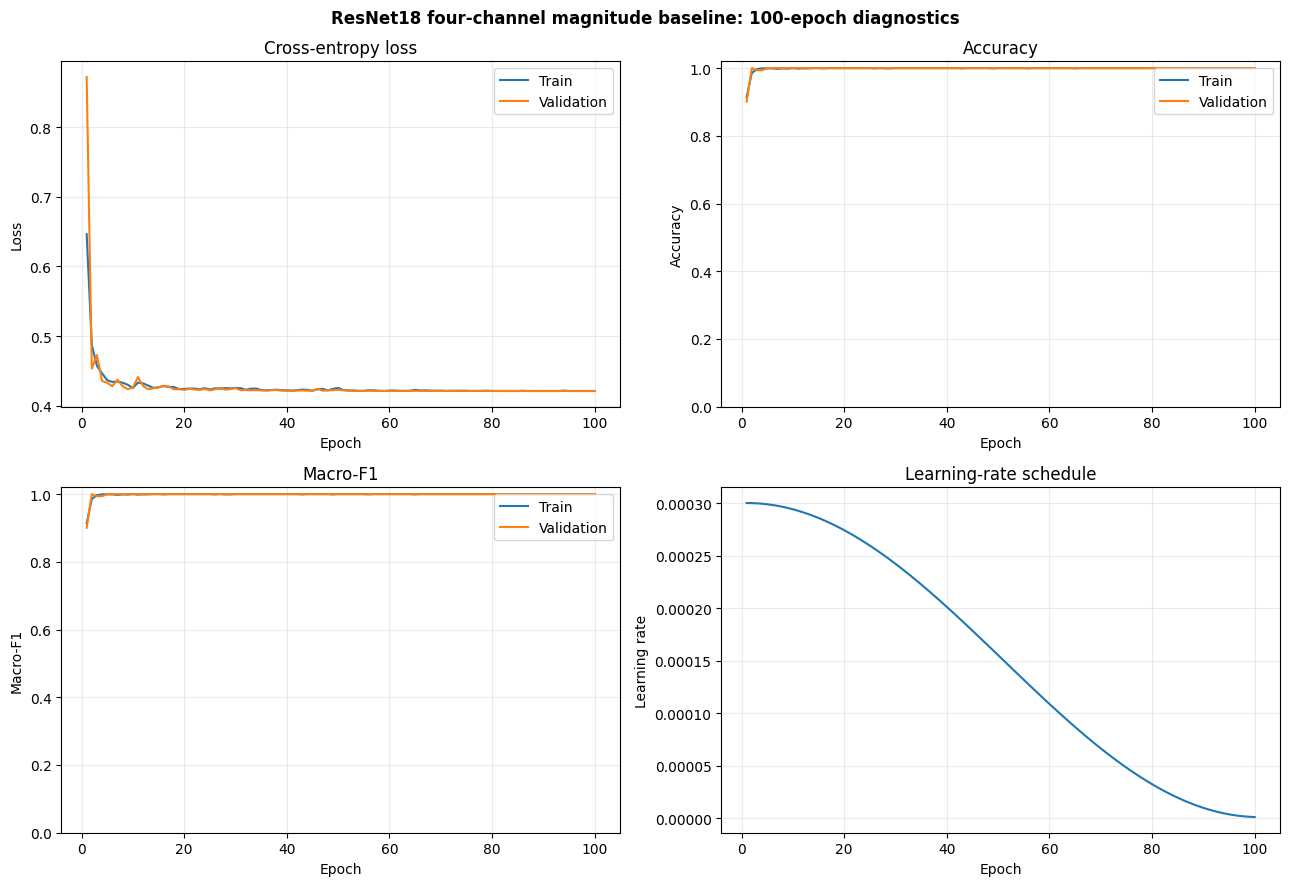

In [11]:
history_df = pd.read_csv(history_path)
best_row = history_df.loc[history_df["valid_f1_macro"].idxmax()]
display(pd.DataFrame([best_row]))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[0, 0].plot(history_df["epoch"], history_df["valid_loss"], label="Validation")
axes[0, 0].set(title="Cross-entropy loss", xlabel="Epoch", ylabel="Loss")
axes[0, 1].plot(history_df["epoch"], history_df["train_accuracy"], label="Train")
axes[0, 1].plot(history_df["epoch"], history_df["valid_accuracy"], label="Validation")
axes[0, 1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.02))
axes[1, 0].plot(history_df["epoch"], history_df["train_f1_macro"], label="Train")
axes[1, 0].plot(history_df["epoch"], history_df["valid_f1_macro"], label="Validation")
axes[1, 0].set(title="Macro-F1", xlabel="Epoch", ylabel="Macro-F1", ylim=(0, 1.02))
axes[1, 1].plot(history_df["epoch"], history_df["learning_rate"])
axes[1, 1].set(title="Learning-rate schedule", xlabel="Epoch", ylabel="Learning rate")
for axis in axes.flat:
    axis.grid(alpha=0.25)
    if len(axis.lines) > 1:
        axis.legend()
fig.suptitle("ResNet18 four-channel magnitude baseline: 100-epoch diagnostics", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "resnet18_100epoch_training_diagnostics.png", dpi=200, bbox_inches="tight")
plt.show()

## Final one-time test evaluation

The checkpoint selected by validation macro-F1 is now loaded. The test split
did not participate in normalization fitting, optimization, scheduling, early
stopping, or model selection.

In [12]:
if not best_checkpoint.exists():
    raise FileNotFoundError("Best validation checkpoint is missing.")
best_payload = torch.load(best_checkpoint, map_location=device, weights_only=False)
model.load_state_dict(best_payload["model"])
selected_epoch = int(best_payload["epoch"])
test_metrics, test_outputs = run_epoch(test_loader, training=False)

report = classification_report(
    test_outputs["targets"],
    test_outputs["predictions"],
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report).T
report_df.to_csv(OUT_DIR / "test_classification_report.csv")

probability_columns = {f"prob_{name}": [row[idx] for row in test_outputs["probabilities"]] for idx, name in enumerate(CLASS_NAMES)}
predictions_df = pd.DataFrame(
    {
        "base": test_outputs["bases"],
        "true_id": test_outputs["targets"],
        "true_class": [CLASS_NAMES[idx] for idx in test_outputs["targets"]],
        "predicted_id": test_outputs["predictions"],
        "predicted_class": [CLASS_NAMES[idx] for idx in test_outputs["predictions"]],
        **probability_columns,
    }
)
predictions_df.to_csv(OUT_DIR / "test_predictions.csv", index=False)

final_results = {
    "selected_epoch": selected_epoch,
    "selection_rule": "highest validation macro-F1; validation loss breaks ties",
    "test_samples": len(test_outputs["targets"]),
    **{f"test_{key}": value for key, value in test_metrics.items()},
}
(OUT_DIR / "final_test_metrics.json").write_text(json.dumps(final_results, indent=2), encoding="utf-8")
print(json.dumps(final_results, indent=2))
display(report_df)

{
  "selected_epoch": 92,
  "selection_rule": "highest validation macro-F1; validation loss breaks ties",
  "test_samples": 162,
  "test_loss": 0.42105556895703444,
  "test_accuracy": 1.0,
  "test_precision_macro": 1.0,
  "test_recall_macro": 1.0,
  "test_f1_macro": 1.0
}


,precision,recall,f1-score,support
Capella,1.0,1.0,1.0,27.0
HISEA1,1.0,1.0,1.0,27.0
QPSSAR,1.0,1.0,1.0,27.0
Radarsat2,1.0,1.0,1.0,27.0
StarLink,1.0,1.0,1.0,27.0
Worldview4,1.0,1.0,1.0,27.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,162.0
weighted avg,1.0,1.0,1.0,162.0


## 13. Test confusion matrices

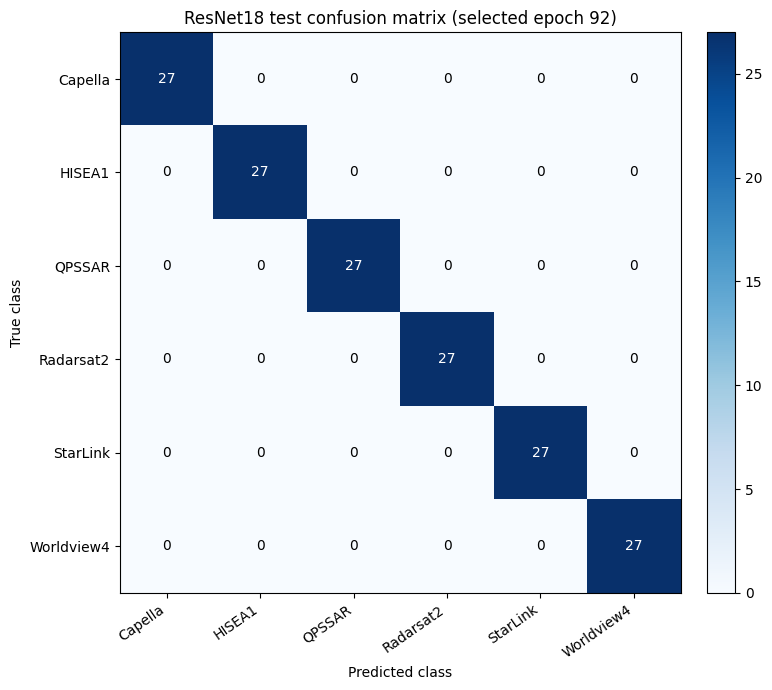

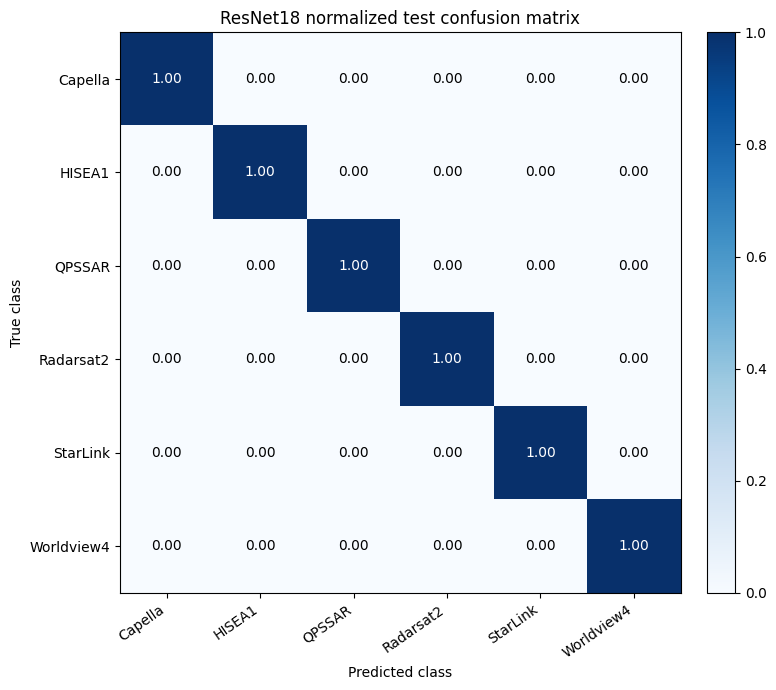

In [13]:
cm = confusion_matrix(test_outputs["targets"], test_outputs["predictions"], labels=range(len(CLASS_NAMES)))
cm_normalized = confusion_matrix(test_outputs["targets"], test_outputs["predictions"], labels=range(len(CLASS_NAMES)), normalize="true")
np.save(OUT_DIR / "test_confusion_matrix_counts.npy", cm)
np.save(OUT_DIR / "test_confusion_matrix_normalized.npy", cm_normalized)


def plot_confusion(matrix: np.ndarray, title: str, destination: Path, normalized: bool) -> None:
    fig, axis = plt.subplots(figsize=(8, 7))
    image = axis.imshow(matrix, cmap="Blues", vmin=0, vmax=1 if normalized else None)
    fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
    axis.set(xticks=range(len(CLASS_NAMES)), yticks=range(len(CLASS_NAMES)), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, xlabel="Predicted class", ylabel="True class", title=title)
    plt.setp(axis.get_xticklabels(), rotation=35, ha="right")
    threshold = matrix.max() / 2 if matrix.size else 0
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            value = f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col]))
            axis.text(col, row, value, ha="center", va="center", color="white" if matrix[row, col] > threshold else "black")
    fig.tight_layout()
    fig.savefig(destination, dpi=200, bbox_inches="tight")
    plt.show()


plot_confusion(cm, f"ResNet18 test confusion matrix (selected epoch {selected_epoch})", OUT_DIR / "test_confusion_matrix_counts.png", normalized=False)
plot_confusion(cm_normalized, "ResNet18 normalized test confusion matrix", OUT_DIR / "test_confusion_matrix_normalized.png", normalized=True)

## 14. Final interpretation checklist

Report the selected epoch, test accuracy, macro-precision, macro-recall, and
macro-F1 from `final_test_metrics.json`. Use the training/validation curves to
discuss model capacity and overfitting. Use the confusion matrix and per-class
report to identify which satellite classes remain difficult.

This experiment is a **magnitude-only conventional CNN baseline**. It must not
be described as using phase or complex-valued convolution. A fair comparison
with ComplexCNN should use the same official split and the same test protocol.

In [14]:
print("Run complete. Results saved under:", OUT_DIR)
print("Use these files in the report/PPT:")
for name in (
    "resnet18_100epoch_training_diagnostics.png",
    "test_confusion_matrix_counts.png",
    "test_confusion_matrix_normalized.png",
    "final_test_metrics.json",
    "test_classification_report.csv",
    "test_predictions.csv",
):
    print(" -", OUT_DIR / name)

Run complete. Results saved under: /content/drive/MyDrive/drdo/outputs/resnet18_100epoch_rigorous
Use these files in the report/PPT:
 - /content/drive/MyDrive/drdo/outputs/resnet18_100epoch_rigorous/resnet18_100epoch_training_diagnostics.png
 - /content/drive/MyDrive/drdo/outputs/resnet18_100epoch_rigorous/test_confusion_matrix_counts.png
 - /content/drive/MyDrive/drdo/outputs/resnet18_100epoch_rigorous/test_confusion_matrix_normalized.png
 - /content/drive/MyDrive/drdo/outputs/resnet18_100epoch_rigorous/final_test_metrics.json
 - /content/drive/MyDrive/drdo/outputs/resnet18_100epoch_rigorous/test_classification_report.csv
 - /content/drive/MyDrive/drdo/outputs/resnet18_100epoch_rigorous/test_predictions.csv
